# Realimentación en lazo cerrado sobre una cámara emulada: las actualizaciones de Nogrette y de Kim

**Pregunta:** ¿Qué hacen las dos actualizaciones publicadas con cámara, el reponderado de Nogrette y la actualización de raíz cuadrada de Kim, de un holograma que parece uniforme en el modelo y 19 por ciento desigual para la cámara, y reproducen los puntos finales publicados en la cámara emulada?

- Nivel: 3, estado del arte. Método ejecutado: M12.
- Requisitos previos: `03-gerchberg-saxton/02-weights-for-uniformity` para el lazo ponderado, y `01-fourier-optics/02-reading-a-trap-array` para la dispersión de las trampas.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de un minuto y medio.

## Objetivos

Un holograma que es uniforme en el papel no es uniforme en el experimento: la luz real difiere del modelo por aberraciones, por la respuesta del dispositivo, por un haz imperfecto. Los experimentos cierran el lazo con una cámara: miran las trampas, encuentran cuáles son más brillantes y cuáles más tenues, cambian los pesos objetivo, recalculan y miran de nuevo. M12 implementa las dos maneras publicadas de hacerlo, sobre una cámara cuyos errores son parámetros declarados. Al terminar puedes:

- decir qué informa la cámara emulada y por qué el informe y las intensidades del modelo discrepan por construcción;
- ejecutar la actualización de Nogrette et al. y la de Kim et al. sobre la misma cámara y leer sus curvas;
- decir qué le hace al lazo el número de iteraciones de Gerchberg-Saxton entre dos mediciones;
- comparar ambos lazos con el mejor holograma en lazo abierto leído por la misma cámara;
- comparar los puntos finales con los publicados sobre tres sorteos de la cámara, y leer cómo depende el lazo de la ganancia de la actualización y del ruido de la cámara.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.camera import EmulatedCamera
from pipeline.model.holo.core.forward import fft_focal_field
from pipeline.model.holo.core.metrics import rel_std, trap_intensities
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.control import m12_closed_loop

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C02 de `data/examples/cases.json`: la tarea de 10 x 10 del tema de optimización con un bloque de realimentación (una ganancia de 0,7, 20 pasos y una cámara cuyo error de ganancia por trampa es 0,19).

- Propietario: este repositorio; el caso es sintético, y los parámetros de cámara del registro siguen la dispersión de lazo abierto de 19 por ciento que informan Nogrette et al.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C02.

In [2]:
# caso C02: la tarea de 10 x 10 con un bloque de realimentación (ganancia 0.7, 20 pasos, error de ganancia
# de la cámara 0.19)
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C02"]
setup = build.setup_of(rec)
target = build.target_of(rec)
traps = target.traps
feedback = rec["feedback"]
print(rec["case_id"], "|", len(traps), "trampas | realimentación:", feedback)

C02_grid_feedback | 100 trampas | realimentación: {'gain': 0.7, 'steps': 20, 'camera': {'gain_rms': 0.19, 'noise_rms': 0.0, 'blur_bins': 0.0}}


## Método

### La cámara emulada, y lo que informa

La cámara emulada del pipeline da a cada trampa una ganancia multiplicativa fija $g_m = \exp(s z_m - s^2/2)$ con $z_m$ un sorteo normal estándar con semilla de la cámara y la trampa, de modo que las ganancias son lognormales con media 1 y un rms relativo de cerca de $s = 0{,}19$. Añade ruido gaussiano y difuminado opcionales, y nunca cambia entre mediciones: una trampa que lee 20 por ciento demasiado brillante sigue haciéndolo. Es una emulación, no un modelo de un sensor: la ganancia representa todo lo que separa la luz real de la intensidad $I_m$ del modelo, y la cámara informa $g_m I_m$. El experimentador ve solo el informe. La primera celda calcula un holograma de GS ponderado para la tarea de 10 x 10 (30 iteraciones) y compara lo que dice el modelo con lo que informa la cámara.

In [3]:
# lo que ve la cámara de un buen holograma: GS ponderado, 30 iteraciones, leído por una cámara emulada
res0 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
camera = EmulatedCamera(seed=101, gain_rms=feedback["camera"]["gain_rms"], noise_rms=0.0, rolloff=False)
true_i = trap_intensities(res0.fields)
seen_i = camera.measure(fft_focal_field(res0.phi, setup), setup, traps)
print(f"dispersión de las intensidades reales: {rel_std(true_i):.2f} %")
print(f"dispersión de las intensidades que informa la cámara: {rel_std(seen_i):.2f} %")
print("ganancias de las cinco primeras trampas:", [round(camera.gain(int(i)), 3) for i in traps.ids[:5]])

dispersión de las intensidades reales: 0.84 %
dispersión de las intensidades que informa la cámara: 19.46 %
ganancias de las cinco primeras trampas: [0.907, 0.802, 0.77, 0.91, 1.26]


El gráfico de dispersión muestra la intensidad informada de cada una de las 100 trampas frente a la del modelo, ambas relativas a sus medias, con la recta identidad.

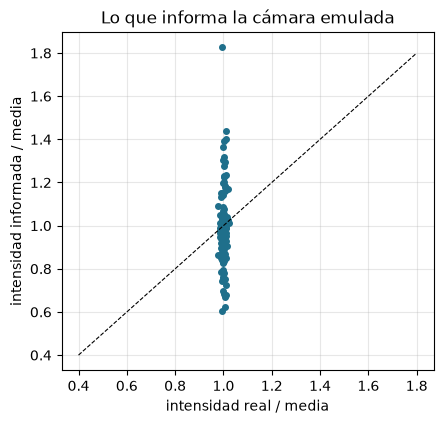

In [4]:
# la intensidad que informa la cámara frente a la real, trampa por trampa, relativa a la media
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.plot(true_i / true_i.mean(), seen_i / seen_i.mean(), "o", markersize=4, color="#1f6f8b")
ax.plot([0.4, 1.8], [0.4, 1.8], "k--", linewidth=0.8)
ax.set_xlabel("intensidad real / media")
ax.set_ylabel("intensidad informada / media")
ax.set_title("Lo que informa la cámara emulada")
ax.grid(True, alpha=0.3)
plt.show()

El modelo dice que las trampas son iguales con una diferencia de 0,84 por ciento, y la cámara informa una dispersión de 19,46 por ciento: las cinco primeras ganancias impresas arriba van de 0,77 a 1,26. En la figura los puntos están sobre una banda horizontal, no sobre la diagonal: las intensidades del modelo son casi todas iguales, y las informadas se reparten en un rango de cerca de 0,6 a 1,5 de la media. Esa es la situación del experimento, y fija lo que el lazo puede y no puede hacer. Puede hacer uniforme lo que informa la cámara, que es la cantidad que grafican las curvas publicadas. No puede hacer más uniformes las intensidades del propio modelo, y no lo hará: si la cámara lee una trampa 25 por ciento alta, el lazo baja esa trampa hasta que el informe sea igual, y la intensidad del modelo ahí queda 20 por ciento baja. La figura no muestra ruido, difuminado ni caída de borde de la cámara, que la cámara puede añadir y este notebook deja en cero.

## Estado del arte

Dos lazos publicados son el estado del arte, y M12 implementa ambos. Nogrette et al. (2014) miden las intensidades de las trampas, reescalan el objetivo de cada trampa por $1 / (1 - G(1 - \rho_m))$ con $\rho_m$ la intensidad medida relativa a la media y $G$ la ganancia, y ejecutan una iteración de Gerchberg-Saxton desde el holograma actual; el artículo informa una dispersión que baja de 19 por ciento rms a 1,4 por ciento en 20 iteraciones con $G = 0{,}7$. Kim et al. (2019) reescalan por la raíz cuadrada de la media sobre la intensidad medida con ganancia completa, congelan la fase focal del holograma actual, e informan 22 por ciento bajando a 1,59 por ciento en tres pasos. No se ejecutó una comparación con el modo de realimentación de slmsuite: espera una cámara de su propia interfaz, y el notebook no construyó ese adaptador, de modo que si su API lo permite con esta emulación queda SIN VERIFICAR. La línea base es el mejor holograma en lazo abierto, M07, leído por la misma cámara. La primera celda ejecuta el lazo de Nogrette durante 20 iteraciones con tres sorteos de la cámara, y compara los puntos finales con los publicados.

In [5]:
# el lazo de Nogrette et al.: ganancia 0.7, 20 iteraciones de realimentación, tres sorteos de cámara
nogrette = {}
for seed in (1, 2, 3):
    cam = EmulatedCamera(seed=100 + seed, gain_rms=0.19, noise_rms=0.0, rolloff=False)
    nogrette[seed] = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(seed), camera=cam)
for seed, res in nogrette.items():
    spread = [h["rel_std"] for h in res.history]
    print(f"sorteo de cámara {seed}: lazo abierto {res.meta['open_loop_rel_std']:.2f} % | "
          f"paso 3 {spread[2]:.2f} % | paso 20 {spread[19]:.2f} % | "
          f"dispersión del modelo en el paso 20 {res.history[19]['rel_std_true']:.2f} %")

sorteo de cámara 1: lazo abierto 19.46 % | paso 3 8.26 % | paso 20 1.41 % | dispersión del modelo en el paso 20 19.35 %
sorteo de cámara 2: lazo abierto 18.25 % | paso 3 6.89 % | paso 20 1.03 % | dispersión del modelo en el paso 20 18.43 %
sorteo de cámara 3: lazo abierto 19.24 % | paso 3 6.65 % | paso 20 0.95 % | dispersión del modelo en el paso 20 18.98 %


La dispersión medida baja de 19,46 por ciento a 8,26 en el paso 3, 4,16 en el paso 5 y 1,41 en el paso 20, que es el 1,4 por ciento publicado. No es monótona: en el paso 10 es 4,41 por ciento, más alta que en el paso 5. La documentación de M12 da una razón probable, que cada iteración interna de Gerchberg-Saxton reintroduce la desigualdad propia del algoritmo entre dos mediciones. La celda lo prueba ejecutando el mismo lazo con tres iteraciones internas en lugar de una.

In [6]:
# el mismo lazo con tres iteraciones de Gerchberg-Saxton entre dos mediciones en lugar de una
cam1b = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=0.0, rolloff=False)
nog3 = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(1), camera=cam1b, n_inner=3)
spread_nog3 = [h["rel_std"] for h in nog3.history]
picked = " ".join(f"{spread_nog3[k]:.2f}" for k in (2, 4, 9, 19))
print(f"n_inner = 3: pasos 3, 5, 10, 20: {picked} %")

n_inner = 3: pasos 3, 5, 10, 20: 7.73 7.30 3.56 5.23 %


Con la ganancia de 0,7 la dispersión medida de los tres sorteos baja de 19,46, 18,25 y 19,24 por ciento a 1,41, 1,03 y 0,95 por ciento en el paso 20, que es el 1,4 por ciento publicado o mejor, y es 8,26, 6,89 y 6,65 por ciento en el paso 3. El segundo lazo es el de Kim et al., ejecutado desde un inicio de GS simple durante tres pasos.

In [7]:
# la variante de Kim et al.: pesos de raíz cuadrada, ganancia completa, tres pasos de realimentación, desde
# un inicio de GS simple
kim = {}
for seed in (1, 2, 3):
    cam = EmulatedCamera(seed=100 + seed, gain_rms=0.19, noise_rms=0.0, rolloff=False)
    kim[seed] = m12_closed_loop.run(setup, target, budget=Budget(3), rng=Rng(seed), camera=cam,
                                    variant="kim", start="gs")
for seed, res in kim.items():
    spread = [h["rel_std"] for h in res.history]
    print(f"sorteo de cámara {seed}: lazo abierto {res.meta['open_loop_rel_std']:.2f} % | "
          f"pasos 1 a 3 {spread[0]:.2f} {spread[1]:.2f} {spread[2]:.2f} %")

sorteo de cámara 1: lazo abierto 28.29 % | pasos 1 a 3 13.59 2.89 1.12 %
sorteo de cámara 2: lazo abierto 26.06 % | pasos 1 a 3 14.04 2.47 1.26 %
sorteo de cámara 3: lazo abierto 27.77 % | pasos 1 a 3 15.09 3.63 1.70 %


El lazo de Kim parte más alto (28,29, 26,06 y 27,77 por ciento), porque un inicio de GS simple es en sí desigual y la cámara añade su propia dispersión, y baja a 1,12, 1,26 y 1,70 por ciento en tres pasos, alrededor del 1,59 por ciento publicado. Para la línea base sin realimentación, la celda lee el holograma WGS de fase fija M07 a través de una cámara con las mismas ganancias.

In [8]:
# la línea base sin realimentación: WGS de fase fija (M07), el mejor holograma en lazo abierto, leído por la
# misma cámara
res07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1))
cam_open = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=0.0, rolloff=False)
seen07 = cam_open.measure(fft_focal_field(res07.phi, setup), setup, traps)
print(f"M07: dispersión de las intensidades reales {rel_std(trap_intensities(res07.fields)):.2f} % | "
      f"dispersión que informa la cámara {rel_std(seen07):.2f} %")

M07: dispersión de las intensidades reales 0.01 % | dispersión que informa la cámara 19.41 %


Las curvas de las seis corridas se dibujan juntas con los dos puntos finales publicados.

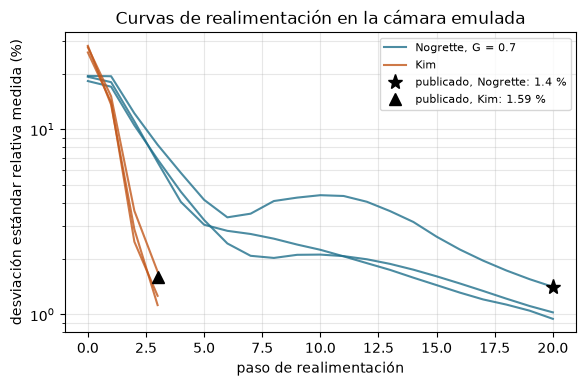

In [9]:
# dispersión medida frente al paso de realimentación para ambos lazos, con los puntos finales publicados
fig, ax = plt.subplots(figsize=(6.6, 3.9))
for seed, res in nogrette.items():
    steps = [0, *[h["iteration"] for h in res.history]]
    spread = [res.meta["open_loop_rel_std"], *[h["rel_std"] for h in res.history]]
    ax.semilogy(steps, spread, color="#1f6f8b", alpha=0.8, label="Nogrette, G = 0.7" if seed == 1 else None)
for seed, res in kim.items():
    steps = [0, *[h["iteration"] for h in res.history]]
    spread = [res.meta["open_loop_rel_std"], *[h["rel_std"] for h in res.history]]
    ax.semilogy(steps, spread, color="#c2571a", alpha=0.8, label="Kim" if seed == 1 else None)
ax.plot([20], [1.4], "k*", markersize=11, label="publicado, Nogrette: 1.4 %")
ax.plot([3], [1.59], "k^", markersize=9, label="publicado, Kim: 1.59 %")
ax.set_xlabel("paso de realimentación")
ax.set_ylabel("desviación estándar relativa medida (%)")
ax.set_title("Curvas de realimentación en la cámara emulada")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()

El lazo de Kim parte más alto, 28,29, 26,06 y 27,77 por ciento, porque un inicio de GS simple es en sí desigual y la cámara añade su propia dispersión encima, donde el inicio publicado es 22 por ciento. Baja a 13,59, 14,04 y 15,09 por ciento tras un paso, y a 1,12, 1,26 y 1,70 por ciento tras tres, alrededor del 1,59 por ciento publicado. El lazo de Nogrette necesita 17 pasos para llegar al nivel que Kim alcanza en tres, y su curva no es monótona: dos de los tres sorteos tienen una meseta o un alza entre los pasos 6 y 12, antes de que la caída se reanude. La documentación propia del pipeline para M12 da una razón probable, que cada iteración interna de Gerchberg-Saxton reintroduce la desigualdad propia del algoritmo entre dos mediciones, pero el notebook no la aisló. La figura muestra concordancia de los puntos finales; no muestra que las curvas concuerden en el medio, porque las curvas publicadas no están disponibles aquí como datos, y no muestra una cámara distinta de la emulada. El mejor holograma en lazo abierto, M07, es igual en 0,01 por ciento en el modelo y es leído como 19,41 por ciento por la misma cámara, el nivel donde parte todo lazo: ninguna cantidad de cómputo en lazo abierto puede conocer las ganancias.

### Lo que añade el emulador: la ganancia de la actualización y el ruido de la cámara

La concordancia con los puntos finales publicados tiene dos límites que conviene decir. La dispersión de lazo abierto de 19 por ciento se eligió como el error de ganancia de la cámara porque el artículo la informa, de modo que el punto de partida coincide por construcción y solo el resultado en lazo cerrado es una prueba; y una cámara emula una cámara publicada, de modo que la concordancia muestra que el lazo y el emulador son coherentes con un resultado publicado, no que el emulador acierte sobre otra. Lo que un emulador puede añadir es lo que el hardware no puede variar a voluntad. La primera celda varía la ganancia $G$ de la actualización, con el sorteo de cámara 1 fijo.

In [10]:
# la ganancia de la actualización: 0.3, 0.5 y 1.0 en el sorteo de cámara 1, junto al 0.7 de la primera corrida
by_gain = {0.7: nogrette[1]}
for gain in (0.3, 0.5, 1.0):
    cam = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=0.0, rolloff=False)
    by_gain[gain] = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(1), camera=cam, gain=gain)
for gain, res in sorted(by_gain.items()):
    spread = np.array([h["rel_std"] for h in res.history])
    first = int(np.argmax(spread <= 2.0)) + 1 if np.any(spread <= 2.0) else None
    print(f"G = {gain}: paso 5 {spread[4]:.2f} % | paso 20 {spread[19]:.2f} % | "
          f"primer paso en o bajo 2 %: {first}")

G = 0.3: paso 5 11.21 % | paso 20 6.22 % | primer paso en o bajo 2 %: None
G = 0.5: paso 5 6.58 % | paso 20 2.56 % | primer paso en o bajo 2 %: None
G = 0.7: paso 5 4.16 % | paso 20 1.41 % | primer paso en o bajo 2 %: 17
G = 1.0: paso 5 2.98 % | paso 20 0.88 % | primer paso en o bajo 2 %: 13


La ganancia importa mucho. Con $G = 0{,}3$ la dispersión sigue en 6,22 por ciento tras 20 pasos y con $G = 0{,}5$ es 2,56; con el 0,7 publicado llega a 1,41 y baja de 2 por ciento en el paso 17, y con $G = 1{,}0$ llega a 0,88 y baja de 2 por ciento en el paso 13. Una ganancia mayor fue mejor en cada paso de este emulador, sin señal de inestabilidad, que una cámara real con ruido podría mostrar. La celda siguiente añade el ruido: ruido gaussiano aditivo de rms 0,0002, 0,0005 y 0,001 en las unidades de la intensidad de una trampa, que para una intensidad media de trampa de cerca de 0,008 es 2,5, 6,2 y 12,5 por ciento de la media.

In [11]:
# ruido de cámara: ruido gaussiano aditivo de 0.0002, 0.0005 y 0.001 (unidades de la intensidad de una
# trampa), ganancia 0.7
floor = {}
for noise in (0.0002, 0.0005, 0.001):
    cam = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=noise, rolloff=False)
    res = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(1), camera=cam)
    mean_trap = res.history[-1]["efficiency"] / len(traps)
    floor[noise] = (100 * noise / mean_trap, float(np.mean([h["rel_std"] for h in res.history[-5:]])))
    print(f"ruido {noise}: ruido relativo a la intensidad media de una trampa "
          f"{floor[noise][0]:.1f} % | dispersión medida, media de los últimos cinco pasos "
          f"{floor[noise][1]:.2f} %")

ruido 0.0002: ruido relativo a la intensidad media de una trampa 2.5 % | dispersión medida, media de los últimos cinco pasos 3.42 %
ruido 0.0005: ruido relativo a la intensidad media de una trampa 6.2 % | dispersión medida, media de los últimos cinco pasos 7.38 %
ruido 0.001: ruido relativo a la intensidad media de una trampa 12.5 % | dispersión medida, media de los últimos cinco pasos 14.36 %


El panel izquierdo grafica las curvas de las cuatro ganancias, y el derecho la dispersión en que se asienta el lazo frente al ruido de la cámara, con la recta en que serían iguales.

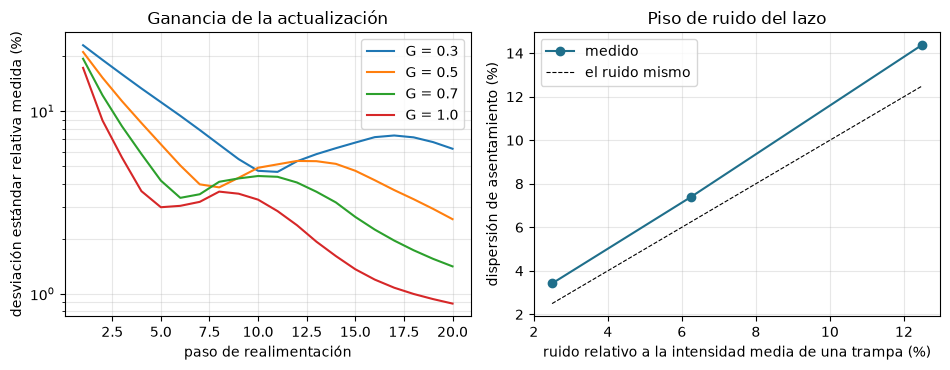

In [12]:
# izquierda: la curva de cada ganancia; derecha: la dispersión en que se asienta el lazo frente al ruido de
# la cámara
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.8))
for gain, res in sorted(by_gain.items()):
    a.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=f"G = {gain}")
a.set_xlabel("paso de realimentación")
a.set_ylabel("desviación estándar relativa medida (%)")
a.set_title("Ganancia de la actualización")
a.legend()
a.grid(True, which="both", alpha=0.3)
relative = [v[0] for v in floor.values()]
settled = [v[1] for v in floor.values()]
b.plot(relative, settled, "o-", color="#1f6f8b", label="medido")
b.plot(relative, relative, "k--", linewidth=0.8, label="el ruido mismo")
b.set_xlabel("ruido relativo a la intensidad media de una trampa (%)")
b.set_ylabel("dispersión de asentamiento (%)")
b.set_title("Piso de ruido del lazo")
b.legend()
b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

El lazo se asienta en una dispersión que sigue el ruido de la cámara y no puede bajar de él: 3,42 por ciento para un ruido de 2,5 por ciento de la trampa media, 7,38 para 6,2 y 14,36 para 12,5, algo sobre el propio ruido en cada caso (el valor medido es de 1,1 a 1,4 veces el ruido relativo a la trampa media). Ese es el límite físico de cualquier realimentación con una cámara ruidosa, ya que una trampa no puede hacerse más uniforme de lo que puede medirse, y es la dependencia que el emulador hace barata de leer: una corrida con hardware necesitaría tres cámaras. En el panel izquierdo las curvas difieren en velocidad y no en forma, y el punto final de Kim de tres pasos queda fuera del alcance de toda ganancia probada para el lazo de Nogrette. La figura no muestra ruido que cambie de un cuadro al siguiente de manera correlacionada, ni un error de ganancia que derive entre pasos, que una cámara real puede tener; el ruido del emulador es independiente en cada cuadro y su ganancia es fija.

## Resultados

**Respuesta:** Las dos actualizaciones publicadas llevan un holograma que la cámara informa 19 por ciento desigual a los puntos finales publicados en la cámara emulada, y el mejor holograma en lazo abierto no puede. Con una ganancia de 0,7 la dispersión informada en tres sorteos de cámara baja de 19,46, 18,25 y 19,24 por ciento a 1,41, 1,03 y 0,95 por ciento en 20 iteraciones, frente al 1,4 por ciento publicado; la actualización de Kim et al., desde un inicio de GS simple, llega a 1,12, 1,26 y 1,70 por ciento en tres pasos frente al 1,59 publicado, donde el lazo de Nogrette tiene 8,26, 6,89 y 6,65 por ciento. La concordancia es solo de los puntos finales, y el 19 por ciento de lazo abierto se fijó a partir del artículo. El holograma WGS de fase fija M07, igual en 0,01 por ciento en el modelo, es leído como 19,41 por ciento por la misma cámara. El lazo es sensible al algoritmo que lleva dentro (con tres iteraciones internas el lazo de Nogrette termina en 5,23 por ciento en lugar de 1,41), a la ganancia (6,22, 2,56, 1,41 y 0,88 por ciento en el paso 20 para G = 0,3, 0,5, 0,7 y 1,0) y al ruido, bajo el cual no puede ir (3,42, 7,38 y 14,36 por ciento para ruido de 2,5, 6,2 y 12,5 por ciento de la trampa media). Los lazos igualan el informe, no el modelo: la dispersión del lado del modelo es cerca de 19 por ciento en el paso 20.

Lo que el notebook no ejecutó es el modo de realimentación de slmsuite, una cámara real, ni ruido correlacionado.

## Resumen

- La cámara emulada informa un holograma uniforme en el modelo como 19,46 por ciento desigual, porque cada trampa tiene una ganancia lognormal fija.
- La actualización de Nogrette et al. llega a 1,41, 1,03 y 0,95 por ciento en el paso 20 en tres sorteos, igual o bajo el 1,4 por ciento publicado; la de Kim et al. llega a 1,12, 1,26 y 1,70 por ciento en tres pasos.
- La concordancia es de los puntos finales, y la dispersión de partida se fijó a partir del artículo.
- Tres iteraciones internas de Gerchberg-Saxton entre mediciones empeoran el lazo de Nogrette; la ganancia de la actualización fija su velocidad y el ruido de la cámara su piso.
- Los lazos igualan el informe y no el modelo.

## Referencias

- Nogrette et al. (2014). Single-atom trapping in holographic 2D arrays of microtraps with arbitrary geometries. Physical Review X 4, 021034. https://arxiv.org/abs/1402.5329
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178